In [1]:
%matplotlib inline
import sys
import numpy as np
import matplotlib.pyplot as plt
import control as ct
sys.path.append("../src")
from metrics import step_metrics

K, tau = 1, 0.5
G = ct.tf([K], [tau, 1])

def make_pid(Kp, Ki=0.0, Kd=0.0):
    C = ct.tf([Kp], [1])
    if Ki != 0:
        C = C + ct.tf([Ki], [1, 0])
    if Kd != 0:
        C = C + ct.tf([Kd, 0], [1])
    return C

In [2]:
L = 0.05                                  # dead time in seconds
num, den = ct.pade(L, 3)                  # 3rd-order Pade approximation of a delay
Gd = G * ct.tf(num, den)                  # motor with dead time

L estimated: 0.05  (model value 0.05)
T estimated: 0.522  (model value 0.5)


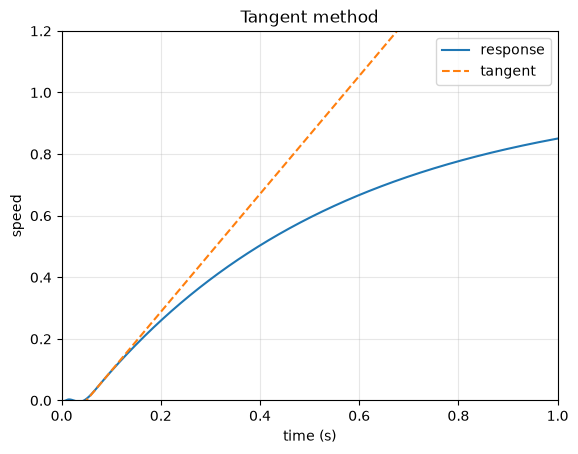

In [3]:
t = np.linspace(0, 5, 5000)
t, y = ct.step_response(Gd, t)

slope = np.gradient(y, t)
i = np.argmax(slope)                              # steepest point
t_L = t[i] - y[i] / slope[i]                      # tangent crosses zero: this is L
t_K = t[i] + (K - y[i]) / slope[i]                # tangent reaches K
L_est, T_est = t_L, t_K - t_L
print("L estimated:", round(L_est, 3), " (model value 0.05)")
print("T estimated:", round(T_est, 3), " (model value 0.5)")

plt.plot(t, y, label="response")
plt.plot(t, y[i] + slope[i] * (t - t[i]), "--", label="tangent")
plt.ylim(0, 1.2); plt.xlim(0, 1)
plt.xlabel("time (s)"); plt.ylabel("speed"); plt.legend(); plt.grid(True, alpha=0.3)
plt.title("Tangent method"); plt.show()

In [4]:
Kp_zn = 1.2 * T_est / (K * L_est)
Ti = 2 * L_est
Td = 0.5 * L_est
Ki_zn = Kp_zn / Ti
Kd_zn = Kp_zn * Td
print(f"Z-N gains: Kp={Kp_zn:.2f}, Ki={Ki_zn:.2f}, Kd={Kd_zn:.3f}")

Z-N gains: Kp=12.58, Ki=126.31, Kd=0.313


manual PI   OS=  4.1%  rise=0.096s  settle=0.303s  sse=-0.000
manual PID  OS= 40.7%  rise=0.071s  settle=0.944s  sse=0.000
Z-N         OS= 79.1%  rise=0.060s  settle=0.458s  sse=0.000


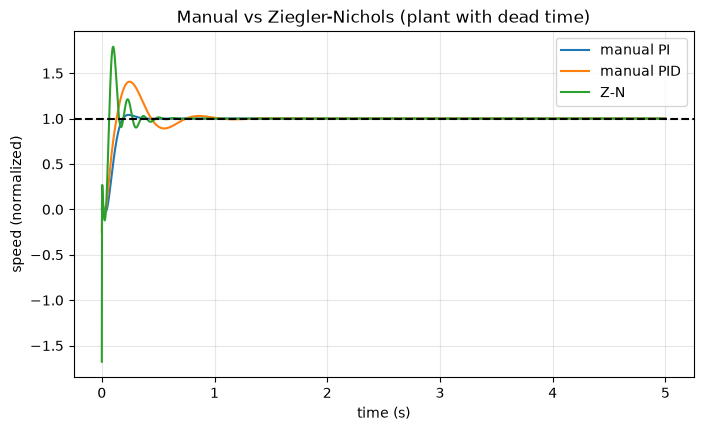

In [5]:
sets = {"manual PI": (5, 10, 0),
        "manual PID": (5, 50, 0.1),
        "Z-N": (Kp_zn, Ki_zn, Kd_zn)}

t = np.linspace(0, 5, 5000)
plt.figure(figsize=(8, 4.5))
for name, (Kp, Ki, Kd) in sets.items():
    T = ct.feedback(make_pid(Kp, Ki, Kd) * Gd, 1)
    t, y = ct.step_response(T, t)
    m = step_metrics(t, y)
    print(f"{name:11} OS={m['overshoot']:5.1f}%  rise={m['rise_time']:.3f}s  "
          f"settle={m['settling_time']:.3f}s  sse={m['sse']:.3f}")
    plt.plot(t, y, label=name)
plt.axhline(1, ls="--", color="k")
plt.xlabel("time (s)"); plt.ylabel("speed (normalized)")
plt.title("Manual vs Ziegler-Nichols (plant with dead time)")
plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig("../plots/zn_vs_manual.png", dpi=150); plt.show()

Z-N rises fastest and overshoots most, because the method tunes for a quarter-decay response (each oscillation peak is a quarter of the previous one), and that is aggressive. Use your own numbers.